In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive
Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


#IMDB Dataset

1641221/1641221 [==============================] - 0s 0us/step
Epoch 1/5
391/391 [==============================] - 38s 84ms/step - loss: 0.6760 - accuracy: 0.5732 - val_loss: 0.6459 - val_accuracy: 0.6285
Epoch 2/5
391/391 [==============================] - 34s 86ms/step - loss: 0.6268 - accuracy: 0.6436 - val_loss: 0.6139 - val_accuracy: 0.6505
Epoch 3/5
391/391 [==============================] - 32s 83ms/step - loss: 0.5775 - accuracy: 0.6888 - val_loss: 0.5967 - val_accuracy: 0.6768
Epoch 4/5
391/391 [==============================] - 32s 81ms/step - loss: 0.5514 - accuracy: 0.7078 - val_loss: 0.5632 - val_accuracy: 0.7011
Epoch 5/5
782/782 [==============================] - 13s 17ms/step - loss: 0.5947 - accuracy: 0.6769
Final Loss: 0.5947, Final Accuracy: 0.6769
782/782 [==============================] - 13s 16ms/step
Precision: 0.8484, Recall: 0.4308


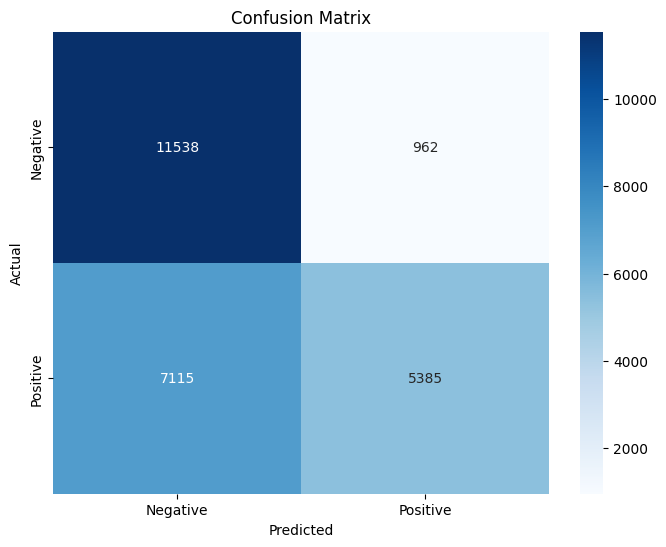

Classification Report:
              precision    recall  f1-score   support

    Negative       0.62      0.92      0.74     12500
    Positive       0.85      0.43      0.57     12500

    accuracy                           0.68     25000
   macro avg       0.73      0.68      0.66     25000
weighted avg       0.73      0.68      0.66     25000



In [3]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

vocab_size = 10000
max_length = 50
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

x_train = pad_sequences(x_train, maxlen=max_length)
x_test = pad_sequences(x_test, maxlen=max_length)

glove_file = '/content/gdrive/MyDrive/glove.6B/glove.6B.100d.txt'
embedding_dim = 100

embeddings_index = {}
with open(glove_file, 'r', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        embeddings_index[word] = coefs

embedding_matrix = np.zeros((vocab_size, embedding_dim))
word_index = imdb.get_word_index()
for word, i in word_index.items():
    if i < vocab_size:
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector

model = Sequential()
model.add(Embedding(vocab_size, embedding_dim, input_length=max_length, weights=[embedding_matrix], trainable=False))
model.add(LSTM(32, return_sequences=True))
model.add(LSTM(64))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.fit(x_train, y_train, epochs=5, batch_size=64, validation_data=(x_test, y_test))

loss, accuracy = model.evaluate(x_test, y_test)
print(f"Final Loss: {loss:.4f}, Final Accuracy: {accuracy:.4f}")

y_pred = (model.predict(x_test) > 0.5).astype("int32")

cm = confusion_matrix(y_test, y_pred)
precision = cm[1, 1] / (cm[1, 1] + cm[0, 1])
recall = cm[1, 1] / (cm[1, 1] + cm[1, 0])

print(f"Precision: {precision:.4f}, Recall: {recall:.4f}")

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

#Persian Dataset

In [3]:
!pip install datasets
from datasets import load_dataset

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 8.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 9.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 9.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.2/401.2 kB 13.8 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface-hub 0.20.3
    Uninstalling huggingface-hub-0.20.3:
      Successfully uninstalled huggingface-hub-0.20.3


In [4]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense, LSTM
from sklearn.metrics import confusion_matrix, precision_score, recall_score
import numpy as np

embedding_dim = 100

persian_dataset = load_dataset("SeyedAli/Persian-Text-Sentiment")

glove_embeddings_index = {}
with open('/content/gdrive/MyDrive/glove.6B/glove.6B.100d.txt', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        glove_embeddings_index[word] = coefs

tokenizer = Tokenizer()
tokenizer.fit_on_texts(persian_dataset['train']['text'])
sequences = tokenizer.texts_to_sequences(persian_dataset['train']['text'])

maxlen = 100
X = pad_sequences(sequences, maxlen=maxlen)
y = np.array(persian_dataset['train']['label'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

word_index = tokenizer.word_index
embedding_matrix = np.zeros((len(word_index) + 1, embedding_dim))
for word, i in word_index.items():
    embedding_vector = glove_embeddings_index.get(word)
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

model = Sequential()
model.add(Embedding(len(word_index) + 1, embedding_dim, weights=[embedding_matrix], input_length=maxlen, trainable=False))
model.add(LSTM(32, return_sequences=True))
model.add(LSTM(64))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_test, y_test))

from sklearn.metrics import confusion_matrix, precision_score, recall_score

y_pred_proba = model.predict(X_test)
y_pred = (y_pred_proba > 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print("Precision:", precision)
print("Recall:", recall)

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Generating train split:   0%|          | 0/55852 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/13964 [00:00<?, ? examples/s]

Epoch 1/5
1397/1397 [==============================] - 25s 14ms/step - loss: 0.6880 - accuracy: 0.5414 - val_loss: 0.6846 - val_accuracy: 0.5493
Epoch 2/5
1397/1397 [==============================] - 18s 13ms/step - loss: 0.6842 - accuracy: 0.5533 - val_loss: 0.6844 - val_accuracy: 0.5509
Epoch 3/5
1397/1397 [==============================] - 17s 12ms/step - loss: 0.6831 - accuracy: 0.5550 - val_loss: 0.6857 - val_accuracy: 0.5469
Epoch 4/5
1397/1397 [==============================] - 20s 14ms/step - loss: 0.6857 - accuracy: 0.5453 - val_loss: 0.6826 - val_accuracy: 0.5547
Epoch 5/5
350/350 [==============================] - 2s 4ms/step
Confusion Matrix:
[[2091 3558]
 [1465 4057]]
Precision: 0.5327642810242942
Recall: 0.7346975733429917
350/350 [==============================] - 2s 5ms/step - loss: 0.6823 - accuracy: 0.5504
Test Loss: 0.6823320984840393
Test Accuracy: 0.5503535866737366


#Third Dataset

In [5]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from datasets import load_dataset
from sklearn.model_selection import train_test_split

dataset = load_dataset("saied/persian_news_dataset", split="train", streaming=True)

docs = []
document_count = 1000
counter = 0
skip_counter = 0

for doc in dataset:
    if len(doc['title']) == 0 or len(doc['category']) == 0:
        skip_counter += 1
        if skip_counter % 10000 == 0:
            print(f'{skip_counter} skipped')
        continue
    docs.append(doc)
    counter += 1
    if counter == document_count:
        break

texts = [doc['text'] for doc in docs]
categories = [doc['category'] for doc in docs]

max_words = 10000
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

input_length = 50
X = pad_sequences(sequences, maxlen=input_length)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(categories)
number_of_classes = len(label_encoder.classes_)
y = tf.keras.utils.to_categorical(y, num_classes=number_of_classes)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

glove_embeddings_index = {}
with open('/content/gdrive/MyDrive/glove.6B/glove.6B.100d.txt', encoding='utf-8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        glove_embeddings_index[word] = coefs

embedding_dim = 100
word_index = tokenizer.word_index
num_words = min(max_words, len(word_index) + 1)
embedding_matrix = np.zeros((num_words, embedding_dim))
for word, i in word_index.items():
    if i >= max_words:
        continue
    embedding_vector = glove_embeddings_index.get(word)
    if embedding_vector is not None:
        embedding_matrix[i] = embedding_vector

model = Sequential()
model.add(Embedding(input_dim=num_words, output_dim=embedding_dim, input_length=input_length))
model.add(LSTM(32, return_sequences=True))
model.add(LSTM(64))
model.add(Dense(6, activation='softmax'))

model.layers[0].set_weights([embedding_matrix])
model.layers[0].trainable = False

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_val, y_val), verbose=2)

val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
y_pred = np.argmax(model.predict(X_val), axis=1)
y_true = np.argmax(y_val, axis=1)

precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')
cm = confusion_matrix(y_true, y_pred)

print(f"Validation Loss: {val_loss}")
print(f"Validation Accuracy: {val_accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")
print("Confusion Matrix:")
print(cm)

/usr/local/lib/python3.10/dist-packages/datasets/load.py:1486: FutureWarning: The repository for saied/persian_news_dataset contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/saied/persian_news_dataset
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this dataset from the next major release of `datasets`.
  warnings.warn(


10000 skipped
20000 skipped
30000 skipped
40000 skipped
50000 skipped
60000 skipped
70000 skipped
80000 skipped
90000 skipped
100000 skipped
110000 skipped
120000 skipped
130000 skipped
140000 skipped
150000 skipped
160000 skipped
170000 skipped
180000 skipped
190000 skipped
200000 skipped
210000 skipped
Epoch 1/5
25/25 - 5s - loss: 1.6854 - accuracy: 0.2925 - val_loss: 1.6707 - val_accuracy: 0.2900 - 5s/epoch - 195ms/step
Epoch 2/5
25/25 - 0s - loss: 1.5728 - accuracy: 0.3550 - val_loss: 1.4882 - val_accuracy: 0.4500 - 302ms/epoch - 12ms/step
Epoch 3/5
25/25 - 0s - loss: 1.3643 - accuracy: 0.5025 - val_loss: 1.3767 - val_accuracy: 0.4600 - 318ms/epoch - 13ms/step
Epoch 4/5
25/25 - 0s - loss: 1.2639 - accuracy: 0.5125 - val_loss: 1.2958 - val_accuracy: 0.5050 - 296ms/epoch - 12ms/step
Epoch 5/5
25/25 - 0s - loss: 1.1950 - accuracy: 0.5487 - val_loss: 1.2807 - val_accuracy: 0.5000 - 205ms/epoch - 8ms/step
7/7 [==============================] - 1s 5ms/step
Validation Loss: 1.280714154243

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
